# Agentic Geo-Spatial Intelligence
## Reproducible exploratory analysis
Use the project Python environment. This notebook reads the compact historical cohort; it does not manufacture delay labels. Figures require the optional matplotlib dependency.

In [1]:
from pathlib import Path
import json
import pandas as pd
import numpy as np
ROOT = Path.cwd() if (Path.cwd()/'data/atlas').exists() else Path.cwd().parent
DATA = ROOT/'data/atlas'
df = pd.read_csv(DATA/'observations.csv', dtype={'mmsi':str})
manifest = json.loads((DATA/'manifest.json').read_text())
benchmark = json.loads((DATA/'benchmark.json').read_text())
print(f'{len(df):,} observations; {df.mmsi.nunique()} vessels')
df.head()

37,843 observations; 217 vessels
        mmsi            timestamp       lat       lon  speed  course              name  type_code  nav_status  length  width  draft vessel_type  storm_lat  storm_lon  storm_distance_nm               h3  course_sin  course_cos  next_speed  next_minutes  anomaly_score  anomaly
0  220129000  2023-08-28T00:00:18  32.01879 -80.46207    0.0   273.2  COLUMBINE MAERSK         70         1.0   346.0   42.0   15.0       Cargo  19.800083 -85.399833             780.28  8544d42bfffffff   -0.998441    0.055822         0.1      6.000000       0.480734    False
1  220129000  2023-08-28T00:06:18  32.01872 -80.46199    0.1   119.5  COLUMBINE MAERSK         70         1.0   346.0   42.0   15.0       Cargo  19.801750 -85.396500             780.12  8544d42bfffffff    0.870356   -0.492424         0.1      6.000000       0.501573    False
2  220129000  2023-08-28T00:12:18  32.01867 -80.46188    0.1   308.3  COLUMBINE MAERSK         70         1.0   346.0   42.0   15.0       C

## Audit and provenance
The missing-value counts in the manifest describe the sampled cohort before validation and binning. The table below describes the final derived observations; denominators differ.

In [2]:
display(pd.Series(manifest))
display(df.isna().mean().sort_values(ascending=False).rename('missing_fraction'))
assert len(df)==manifest['observations']
assert not df.duplicated(['mmsi','timestamp']).any()

source                                                   AIS_2023_08_28.csv
source_url                https://coast.noaa.gov/htdata/CMSP/AISDataHand...
source_bytes                                                      998470038
raw_rows                                                            9306345
region_rows                                                         1538134
cohort_rows                                                          122629
invalid_rows                                                          25113
duplicate_rows                                                            6
resampled_rows_removed                                                59667
observations                                                          37843
vessels                                                                 217
missing_fields            {'MMSI': 0, 'BaseDateTime': 0, 'LAT': 0, 'LON'...
start                                                   2023-08-28T00:00:00
end         

## Descriptive statistics
A mean over observations weights vessels with more retained reports more heavily. Compare it with a mean of per-vessel means.

In [3]:
display(df[['speed','storm_distance_nm','length','width','draft']].describe())
print('Observation-weighted mean:',df.speed.mean())
print('Vessel-weighted mean:',df.groupby('mmsi').speed.mean().mean())
display(df.groupby('vessel_type').agg(vessels=('mmsi','nunique'),observations=('mmsi','size'),mean_speed=('speed','mean')))

              speed  storm_distance_nm        length         width         draft
count  37843.000000       37843.000000  33792.000000  28473.000000  13993.000000
mean       2.253133         567.403159     66.549923     13.400309      6.445108
std        4.618413         133.708505     87.717409     12.219398      3.880380
min        0.000000         200.500000      0.000000      0.000000      0.000000
25%        0.000000         462.215000     15.000000      6.000000      3.000000
50%        0.000000         564.420000     24.000000      8.000000      5.900000
75%        1.100000         638.580000     69.000000     18.000000     10.000000
max       59.300000        1008.370000    369.000000     55.000000     15.000000
Observation-weighted mean: 2.253132679755833
Vessel-weighted mean: 3.5495280049109597
             vessels  observations  mean_speed
vessel_type                                   
Cargo             29          6010    5.086256
Fishing           14          2662    2.5951

## Spatial and temporal exploration
H3 cells count unique vessels over the day, not simultaneous congestion. Summing per-cell vessel counts double-counts moving vessels.

In [4]:
display(df.groupby('h3').agg(vessels=('mmsi','nunique'),observations=('mmsi','size')).sort_values('vessels',ascending=False).head(10))
display(df.assign(hour=df.timestamp.str[11:13]).groupby('hour').agg(observations=('mmsi','size'),mean_speed=('speed','mean')))

                 vessels  observations
h3                                    
8544a113fffffff       15          1889
8544465bfffffff       14          1371
8544a13bfffffff       12          1381
8544ab97fffffff        9          1483
85447337fffffff        8           870
85444643fffffff        8            40
8544a10ffffffff        8           624
85441e67fffffff        8           168
854473c7fffffff        8           385
8544d073fffffff        8           502
      observations  mean_speed
hour                          
00            1569    2.285405
01            1616    2.477785
02            1574    2.349873
03            1560    2.187179
04            1535    2.027231
05            1553    2.082421
06            1482    2.085628
07            1593    2.101946
08            1599    2.006754
09            1585    2.230662
10            1606    2.253300
11            1636    2.442910
12            1650    2.445818
13            1641    2.261913
14            1613    2.212647
15   

## Charts
Optional: install matplotlib into the same environment. The dashboard already provides interactive versions of these plots.

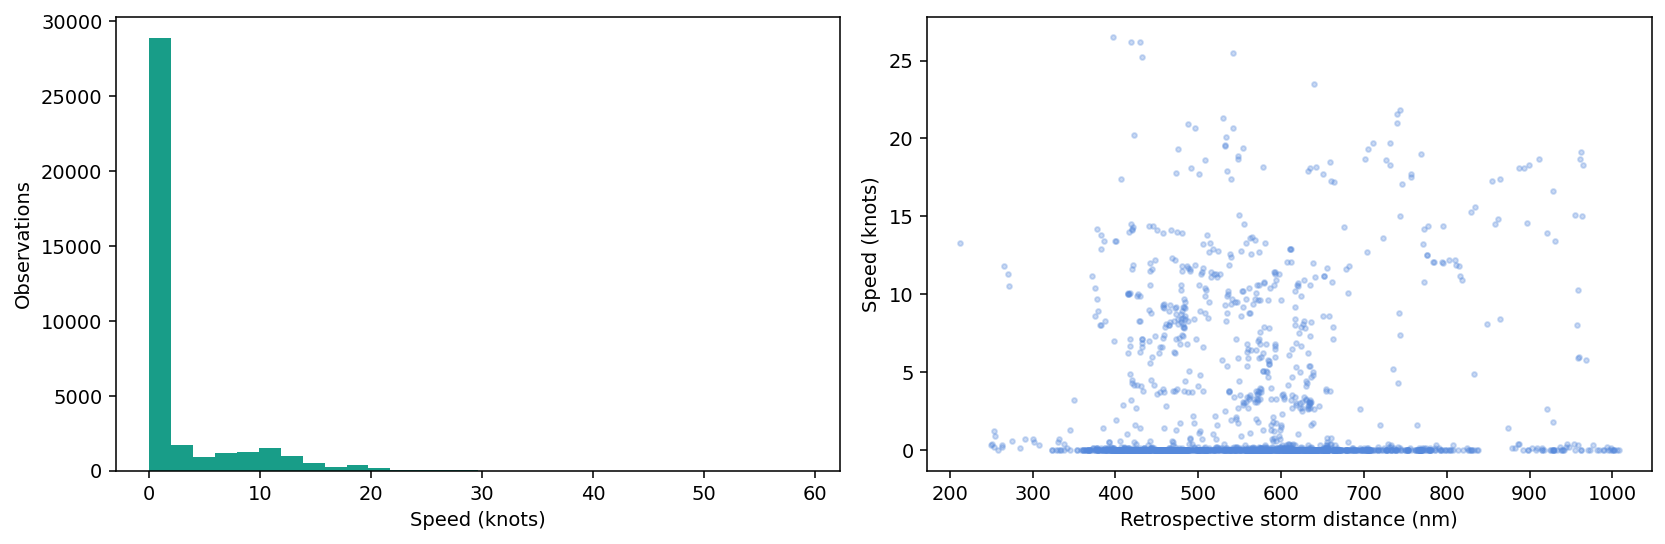

In [5]:
import matplotlib.pyplot as plt
fig,ax=plt.subplots(1,2,figsize=(12,4))
ax[0].hist(df.speed,bins=30,color='#189d88');ax[0].set(xlabel='Speed (knots)',ylabel='Observations')
sample=df.sample(min(2000,len(df)),random_state=42)
ax[1].scatter(sample.storm_distance_nm,sample.speed,s=6,alpha=.3,color='#5689db');ax[1].set(xlabel='Retrospective storm distance (nm)',ylabel='Speed (knots)')
plt.tight_layout()

## Correlation is not causation
Retrospective storm distance is excluded from forecast features. Course has circular features because 359 degrees is close to 1 degree.

In [6]:
df[['speed','lat','lon','storm_distance_nm','length','draft']].corr()

                      speed       lat       lon  storm_distance_nm    length     draft
speed              1.000000  0.013430  0.048440           0.051893  0.360054  0.227536
lat                0.013430  1.000000 -0.113689           0.939809  0.228131  0.415278
lon                0.048440 -0.113689  1.000000           0.013123  0.058183  0.087397
storm_distance_nm  0.051893  0.939809  0.013123           1.000000  0.254964  0.411189
length             0.360054  0.228131  0.058183           0.254964  1.000000  0.833903
draft              0.227536  0.415278  0.087397           0.411189  0.833903  1.000000


## Common held-out experiment
The benchmark uses whole-vessel separation. Persistence is the strongest MAE baseline in the recorded run. Do not select hyperparameters on these test scores.

In [7]:
display(pd.DataFrame(benchmark['results']))
display(pd.DataFrame(benchmark['subgroups']))
display(pd.DataFrame(benchmark['feature_importance']))
assert benchmark['overlapping_vessels']==0
print('Cluster bootstrap MAE interval:',benchmark['mae_cluster_bootstrap_95ci'])

                  model     mae    rmse      r2  train_seconds
0  Persistence baseline  0.3498  1.5182  0.8990          0.000
1       Training median  2.3362  5.3171 -0.2392          0.000
2      Ridge regression  0.4368  1.4974  0.9017          0.015
3         Random forest  0.5385  1.5008  0.9013          1.839
4     Gradient boosting  0.4878  1.4886  0.9029          0.103
                          group     n  persistence_mae  boosting_mae
0  Stationary or slow (<0.5 kn)  7194           0.0918        0.1550
1             Moving (>=0.5 kn)  2791           1.0148        1.3456
2      Short horizon (2–10 min)  9747           0.3560        0.4963
3   Longer horizon (>10–30 min)   238           0.0958        0.1399
      feature  increase_mae     std
0       speed        3.4249  0.0257
1  course_sin        0.0285  0.0033
2  course_cos        0.0124  0.0032
3         lat       -0.0088  0.0016
4         lon        0.0390  0.0082
5   type_code        0.0016  0.0037
Cluster bootstrap MAE int

## Questions for the team
1. Why are there 217 observed vessels but only 202 with eligible prediction targets?
2. How does dropping unknown course values change the cohort?
3. Why do MAE and RMSE rank the methods differently?
4. What additional data are required before predicting actual arrival delay or fuel consumption?